In [1]:
import pandas as pd 
import numpy as np 
import polars as pl
from typing import List
from collections import Counter
import glob, os

import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats("retina")
from matplotlib.ticker import FuncFormatter
import matplotlib as mpl
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "sans-serif"],
    "font.size": 12,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})


import yaml
with open("../../src/configs.yml", "r") as configs:
    configs = yaml.safe_load(configs)

DATAPATH = configs["SERVER_DATA"]
ROOTPATH = configs["SERVER_WD"]

### load subreddit networks

In [2]:
import graph_tool.all as gt 
from graph_tool.all import load_graph
from src.utils.graph_tool_functions import extract_subgraph, remove_user_page_nodes

input_fpath = "/cinddata/Reddit_processed/comments_submissions/networks/filtered"
# input_fpath = "/cinddata/Reddit_processed/comments_submissions/networks/full"
years = range(2006, 2020)
g_dict = {}
g_filtered_dict = {}
g_sub_dict = {}
seed_nodes = ["the_donald"]
network_stats = []
for y in years:
    print(f"loading/extracting for year {y}:")
    # g = load_graph(f"{input_fpath}/{y}.gt.gz")
    g = load_graph(f"{input_fpath}/{y}_2.gt.gz")
    g_filtered = remove_user_page_nodes(g)
    g_sub = extract_subgraph(g_filtered, seed_nodes)
    g_dict[y] = g
    g_filtered_dict[y] = g_filtered
    g_sub_dict[y] = g_sub

    network_stats.append({
        "year": y,
        "original_n_nodes": g.num_vertices(),
        "original_n_edges": g.num_edges(),
        "filtered_n_nodes": g_filtered.num_vertices(),
        "filtered_n_edges": g_filtered.num_edges(),
        "subgraph_n_nodes": g_sub.num_vertices(),
        "subgraph_n_edges": g_sub.num_edges(),
    })
network_stats_df = pd.DataFrame(network_stats)
display(network_stats_df)

loading/extracting for year 2006:
Removed 0 u_ nodes and 0 associated edges.


/home/yijingch@kite.upenn.edu/.conda/envs/reddit-ban-2020/lib/python3.9/site-packages/graph_tool/draw/cairo_draw.py:1553: RuntimeWarning: Error importing Gtk module: ; GTK+ drawing will not work.
  warnings.warn(msg, RuntimeWarning)


Extracting neighbors: 0it [00:00, ?it/s]

setting vertex filter...
pruning graph...
Seeds found: 0 Missing: 1
Expanded subgraph: 0 vertices; 0 edges
Missing seed names (not found): ['the_donald'] 
loading/extracting for year 2007:
Removed 0 u_ nodes and 0 associated edges.


Extracting neighbors: 0it [00:00, ?it/s]

setting vertex filter...
pruning graph...
Seeds found: 0 Missing: 1
Expanded subgraph: 0 vertices; 0 edges
Missing seed names (not found): ['the_donald'] 
loading/extracting for year 2008:
Removed 0 u_ nodes and 0 associated edges.


... (21 outputs left out)

setting vertex filter...
pruning graph...
Seeds found: 1 Missing: 0
Expanded subgraph: 50794 vertices; 95465431 edges
loading/extracting for year 2019:
Removed 0 u_ nodes and 0 associated edges.


Extracting neighbors:   0%|          | 0/1 [00:00<?, ?it/s]

setting vertex filter...
pruning graph...
Seeds found: 1 Missing: 0
Expanded subgraph: 58523 vertices; 124249793 edges


,year,original_n_nodes,original_n_edges,filtered_n_nodes,filtered_n_edges,subgraph_n_nodes,subgraph_n_edges
0,2006,34,165,34,165,0,0
1,2007,37,237,37,237,0,0
2,2008,1123,39595,1123,39595,0,0
3,2009,2909,187193,2909,187193,0,0
4,2010,6460,716794,6460,716794,0,0
5,2011,15961,2997913,15961,2997913,0,0
6,2012,34260,8871604,34259,8871579,0,0
7,2013,49634,15248071,49634,15248071,0,0
8,2014,71296,25004758,71295,25004719,0,0
9,2015,181203,53074772,181202,53074766,8312,16901298


## load subreddit sets

In [3]:
sets_df = pd.read_csv("../../data-public/subreddit_sets.csv")

subreddit_sets = {
    name: set(group["subreddit"])
    for name, group in sets_df.groupby("set")
}

matched1_indp = subreddit_sets["matched1_indp"]
matched2_indp= subreddit_sets["matched2_indp"]
matched2_conn = subreddit_sets["matched2_conn"]
random = subreddit_sets["random"]
banned = subreddit_sets["banned"]

In [4]:
def normalize_subreddit(x):
    return str(x).lower().strip()

banned_set = {normalize_subreddit(x) for x in banned}
focal = "the_donald"


neighbor_sets = {}
banned_neighbor_sets = {}
neighbor_rows = []

for year in range(2015, 2020):

    g = g_sub_dict[year]
    names = g.vp["name"]

    name_to_vertex = {
        normalize_subreddit(names[v]): v
        for v in g.vertices()
    }

    focal_v = name_to_vertex[focal]

    neighbors = {
        normalize_subreddit(names[v])
        for v in focal_v.all_neighbors()
    }

    banned_neighbors = neighbors.intersection(banned_set)

    neighbor_sets[year] = neighbors
    banned_neighbor_sets[year] = banned_neighbors

    neighbor_rows.append({
        "year": year,
        "n_neighbors": len(neighbors),
        "n_banned_neighbors": len(banned_neighbors),
    })

neighbor_count_df = pd.DataFrame(neighbor_rows)
neighbor_count_df

,year,n_neighbors,n_banned_neighbors
0,2015,8311,33
1,2016,56469,216
2,2017,52252,252
3,2018,50793,294
4,2019,58522,610


/tmp/ipykernel_986986/1224713321.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


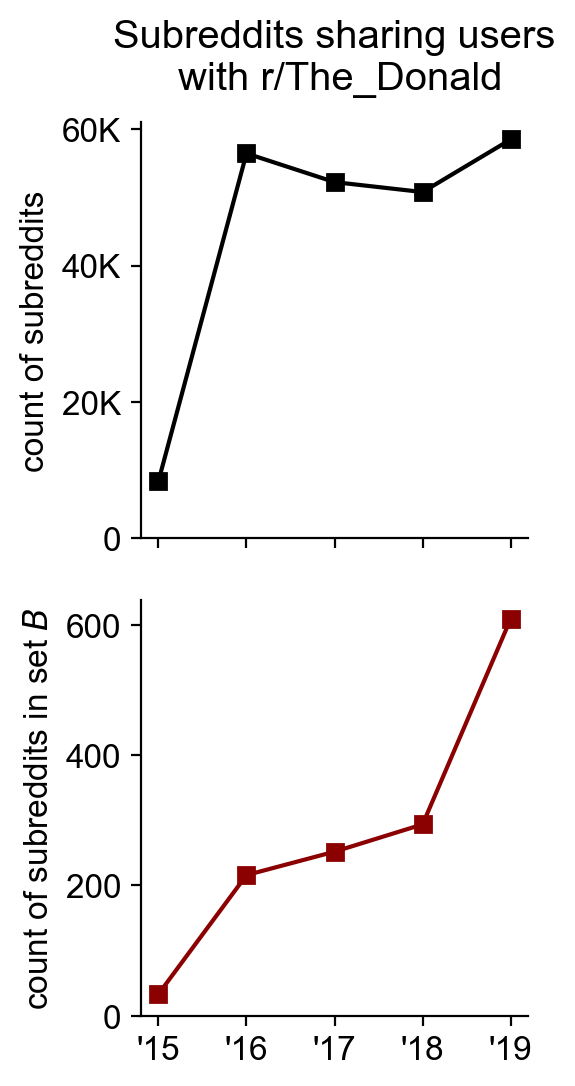

In [5]:
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(2.5,5.8), sharex=True,
    gridspec_kw={"hspace": 0.15},
)

years = neighbor_count_df["year"]

ax1.plot(years, neighbor_count_df["n_neighbors"], color="black", marker="s")
ax1.set_ylabel("count of subreddits")
ax1.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x/1000:g}K" if x else "0"))
ax1.set_title("Subreddits sharing users\n with r/The_Donald", pad=12)
# ax1.text(0.02, 0.95, "All neighbors", transform=ax1.transAxes, va="top")

ax2.plot(years, neighbor_count_df["n_banned_neighbors"], color="darkred", marker="s")
ax2.set_ylabel(r"count of subreddits in set $B$")
# ax2.text(0.02, 0.95, "Banned neighbors", transform=ax2.transAxes, va="top")
ax2.set_xticks(range(2015, 2020))
ax2.set_xticklabels([f"'{str(year)[-2:]}" for year in range(2015, 2020)])
# ax2.set_xlabel("year")

for ax in (ax1, ax2):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylim(bottom=0)

plt.tight_layout()
# plt.savefig("../../output/mainbody/ego_the_donald_neighbors_banned_count.png",dpi=300, bbox_inches="tight")
# plt.savefig("../../output/mainbody/ego_the_donald_neighbors_banned_count.pdf",dpi=300, bbox_inches="tight")